# 3D Cosmic Web — 150,000 Real SDSS DR17 Galaxies on Vulkan GPU (`vkastro` + `vkshader`)

Maps **150,000 real extragalactic galaxies** from the **Sloan Digital Sky Survey (SDSS DR17)** into true **3D cosmological space (Megaparsecs)** on Vulkan GPU:
- **`vkastro.FlatLambdaCDM`**: converts every galaxy's spectroscopic redshift $z$ into **comoving distance $D_C(z)$ in Megaparsecs** (1 Mpc = 3.26 million light-years) on GPU.
- **`vkastro.SkyCoord`**: converts `(RA, Dec, D_C)` → 3D Cartesian `(X_Mpc, Y_Mpc, Z_Mpc)` and Galactic `(l, b)` coordinates.
- **`vkplot` & `vkcolorcet`**: renders the **Galaxy Color–Magnitude Diagram** (Red Sequence ellipticals vs. Blue Cloud spirals) and the **Cosmic Web** slice.
- **`vkshader.interact_3d`**: interactive 3D fly-through of galaxy **filaments, superclusters, and cosmic voids** spanning over **2 billion light-years**!
- **`vklearn.KMeans`**: discovers 3D galaxy supercluster overdensities on GPU.

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vknumpy as vnp
import vkpandas as vpd
import vkastro as vka
import vkshader as vks
import vkpanel as pn
import vkplot.vkpandas  # registers .vkplot

sdss_path = Path.home() / ".cache/vkdata/astro/sdss_galaxies.parq"
t0 = time.perf_counter()
gal = vpd.read_parquet(sdss_path)

# Cosmological distances on Vulkan GPU (H0=70 km/s/Mpc, Om0=0.3)
cosmo = vka.FlatLambdaCDM(H0=70.0, Om0=0.3)
dc_mpc = cosmo.comoving_distance(gal["z"])
distmod = cosmo.distmod(gal["z"])
abs_r = gal["r"].values.astype(np.float32) - distmod
g_minus_r = gal["g"].values.astype(np.float32) - gal["r"].values.astype(np.float32)

# 3D Cartesian coordinates in Megaparsecs (Mpc)
sc = vka.SkyCoord(gal["ra"], gal["dec"], distance=dc_mpc, frame="icrs")
x_mpc, y_mpc, z_mpc = sc.cartesian()

gal["dc_mpc"]    = dc_mpc
gal["abs_r"]     = abs_r
gal["neg_abs_r"] = -abs_r  # brighter galaxies at top
gal["g_minus_r"] = g_minus_r
gal["x_mpc"]     = x_mpc
gal["y_mpc"]     = y_mpc
gal["z_mpc"]     = z_mpc

# Galaxy color class: 0 = Blue Cloud (star-forming spirals), 1 = Green Valley, 2 = Red Sequence (ellipticals)
gr_np = g_minus_r.to_numpy()
gal_cls = np.digitize(gr_np, bins=[0.70, 0.92]).astype(np.int32)
gal["gal_class"] = vnp.array(gal_cls, dtype=np.int32)

print(f"Loaded & mapped {len(gal):,} real SDSS DR17 galaxies into 3D Mpc on GPU in {(time.perf_counter()-t0)*1000:.1f} ms")
print(f"Redshift z: {float(gal['z'].min()):.4f} .. {float(gal['z'].max()):.4f} | Comoving distance: {float(dc_mpc.min().item()):.1f} .. {float(dc_mpc.max().item()):.1f} Mpc")
# Fit GPU KMeans (k=8) in 3D comoving space so we can also visualize clusters in 3D!
from vklearn import KMeans
import vkcolorcet as cc
t_km = time.perf_counter()
km = KMeans(n_clusters=8, max_iter=20, random_state=42).fit(gal[["x_mpc", "y_mpc", "z_mpc"]])
km_ms = (time.perf_counter() - t_km) * 1000.0
gal["km_cluster"] = km.predict(gal[["x_mpc", "y_mpc", "z_mpc"]])
print(f"GPU KMeans (k=8) on {len(gal):,} 3D galaxies finished in {km_ms:.1f} ms")


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Loaded & mapped 150,000 real SDSS DR17 galaxies into 3D Mpc on GPU in 601.5 ms


[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Redshift z: 0.0050 .. 0.2128 | Comoving distance: 21.4 .. 866.2 Mpc
GPU KMeans (k=8) on 150,000 3D galaxies finished in 6655.2 ms


## 1. Galaxy Color–Magnitude Diagram & 2D Cosmic Web Slice

### What you're seeing:
- **Left — Galaxy Color–Magnitude Diagram (`g - r` vs. `-M_r`)**:
  - **Horizontal axis (`g - r` color)**: optical color from **young, blue star-forming spiral galaxies (left)** to **older, red elliptical galaxies (right)**.
  - **Vertical axis (`-M_r`)**: intrinsic brightness in the red band (brighter, more massive galaxies toward the top).
  - Notice the famous **bimodality**: the bright, tight **Red Sequence** on the right (massive passive ellipticals) separated from the **Blue Cloud** on the left (active star-forming spirals).
- **Right — Cosmic Web Slice (`X_Mpc` vs. `Y_Mpc`)**:
  - A top-down slice of the Universe in **Megaparsecs** centered on the Milky Way `(0, 0)`.
  - Instead of uniform random noise, galaxies form a vast sponge-like **Cosmic Web** of dense **filaments**, bright **supercluster knots**, and dark **cosmic voids** hundreds of millions of light-years across.

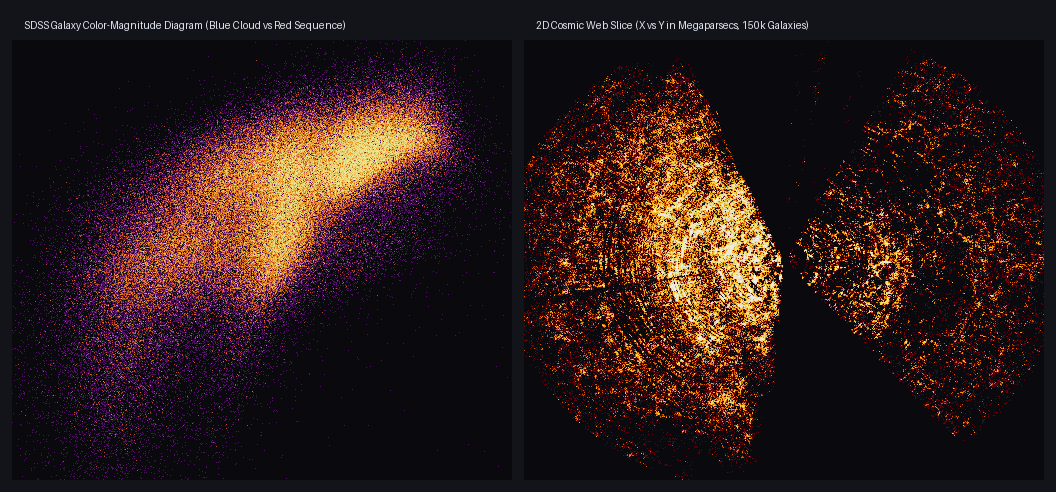

In [2]:
cmd = gal.vkplot.points(
    "g_minus_r", "neg_abs_r", cmap="inferno", how="eq_hist",
    width=500, height=440, xlim=(0.1, 1.6), ylim=(17.0, 23.8),
    title="SDSS Galaxy Color-Magnitude Diagram (Blue Cloud vs Red Sequence)",
)
wedge = gal.vkplot.points(
    "x_mpc", "y_mpc", cmap="fire", how="eq_hist",
    width=520, height=440, xlim=(-800.0, 800.0), ylim=(-800.0, 800.0),
    title="2D Cosmic Web Slice (X vs Y in Megaparsecs, 150k Galaxies)",
)
(cmd + wedge).cols(2)

## 2. Interactive 3D Cosmic Web Fly-Through (`vkshader.interact_3d`)

### What you're seeing:
- Every dot is an **entire galaxy** (billions of stars!) placed at its real 3D comoving position `(X_Mpc, Y_Mpc, Z_Mpc)` in **Megaparsecs**, with the Milky Way at `(0, 0, 0)`.
- **Galaxy Type color mode**:
  - **Blue (`#4da6ff`)** = Blue Cloud star-forming spiral galaxies (often tracing filaments and void edges)
  - **Gold (`#ffe066`)** = Green Valley transitional galaxies
  - **Red-Orange (`#ff5c33`)** = Red Sequence massive ellipticals (strongly concentrated in dense supercluster cores!)
- **Controls:** **Drag** to orbit in 3D · **Shift+Drag / Right-Drag** to fly/pan · **Scroll** to zoom · **Double-click** to reset · Use **Region** to zoom into the **Local Universe (`±300 Mpc`)** or view the **Full SDSS Volume (`±800 Mpc`)**.- **KMeans 3D Clusters mode**: colors each galaxy by which of the **8 GPU K-Means Voronoi regions** it belongs to (using `vkcolorcet.glasbey_dark`), so you can visually see how K-Means partitions the 3D survey volume!


In [3]:
regions_3d = {
    "Full SDSS Volume (±800 Mpc)": ((-800.0, 800.0), (-800.0, 800.0)),
    "Local Superclusters (±350 Mpc)": ((-350.0, 350.0), (-350.0, 350.0)),
    "Nearby Universe (±150 Mpc)": ((-150.0, 150.0), (-150.0, 150.0)),
}
color_modes_3d = {
    "KMeans 3D Clusters (8 Regions)": ("km_cluster", cc.glasbey_dark[:8]),
    "Galaxy Type (Blue Spirals / Gold / Red Ellipticals)": ("gal_class", ["#4da6ff", "#ffe066", "#ff5c33"]),
    "Z Coordinate Height (Fire)": (None, None),
}

vks.interact_3d(
    gal, "x_mpc", "y_mpc", "z_mpc",
    width=840, height=540,
    z_range=(-450.0, 650.0),
    kind="points",
    color_modes=color_modes_3d,
    regions=regions_3d,
    basemap=None,
    z_scale=0.80,
);

## 3. Redshift & Distance Distributions + GPU `vklearn.KMeans` Supercluster Finder

### What you're seeing:
- **Left — Spectroscopic Redshift ($z$) Histogram**: shows the distribution of galaxies out to $z = 0.22$ (~2.6 billion light-years lookback distance).
- **Right — Comoving Distance (`dc_mpc`) Histogram**: peaks around ~300–500 Mpc where the survey volume is large while galaxies are still bright enough for SDSS spectroscopy.
- **Bottom Table — GPU `vklearn.KMeans`**: clusters all 150,000 galaxies in 3D `(X_Mpc, Y_Mpc, Z_Mpc)` space to locate 8 major supercluster regions.  - Each cluster is a broad 3D Voronoi sector of the SDSS footprint (hundreds of Mpc wide, centered on major galaxy overdensities); `X/Y/Z (Mpc)` is the center of mass and `Dist (Mpc)` is its comoving distance from Earth (1 Mpc ≈ 3.26 million light-years).


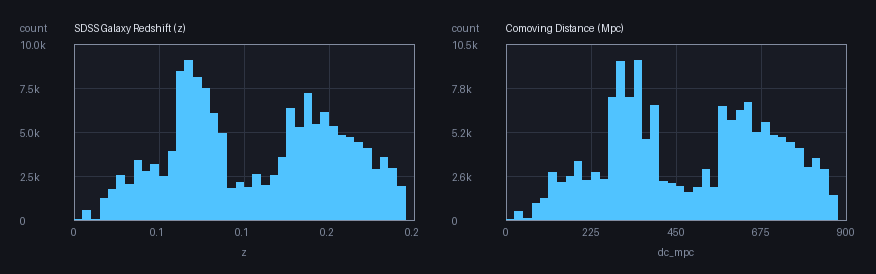

In [4]:
from vklearn import KMeans

h_z  = gal.vkplot.hist("z", bins=40, range=(0.0, 0.22), width=420, height=250, title="SDSS Galaxy Redshift (z)")
h_dc = gal.vkplot.hist("dc_mpc", bins=40, range=(0.0, 900.0), width=420, height=250, title="Comoving Distance (Mpc)")
(h_z + h_dc).cols(2)

In [5]:
centers = km.cluster_centers_.to_numpy()
counts = vnp.bincount(gal["km_cluster"].values, minlength=8).to_numpy()
r_mpc = np.sqrt((centers ** 2).sum(axis=1))

rows = {
    "Cluster": [f"#{i}" for i in range(8)],
    "Galaxies": [f"{int(counts[i]):,}" for i in range(8)],
    "X (Mpc)": [round(float(centers[i, 0]), 1) for i in range(8)],
    "Y (Mpc)": [round(float(centers[i, 1]), 1) for i in range(8)],
    "Z (Mpc)": [round(float(centers[i, 2]), 1) for i in range(8)],
    "Dist (Mpc)": [round(float(r_mpc[i]), 1) for i in range(8)],
}
pn.Card(pn.DataTable(rows, max_rows=10), title="3D Galaxy Regions (Vulkan GPU KMeans, k=8)")